# CC2017 - Deep Learning - Proyecto Final
## 06 - Robustez ante perturbaciones

Se evalua la CNN sobre el test oficial con tres niveles de brillo reducido, ruido gaussiano y desenfoque. El nivel cero corresponde a las imagenes originales.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
from experiments.run_robustness import evaluate, save_outputs
results = evaluate(ROOT / 'outputs' / 'cnn_scratch.pt')
save_outputs(results, ROOT / 'outputs')
results.round(4)

sin_perturbacion   nivel 0: accuracy=0.9918, F1 macro=0.9870, 18s


brillo             nivel 1: accuracy=0.9914, F1 macro=0.9857, 18s


brillo             nivel 2: accuracy=0.9872, F1 macro=0.9764, 18s


brillo             nivel 3: accuracy=0.9815, F1 macro=0.9690, 18s


ruido_gaussiano    nivel 1: accuracy=0.9569, F1 macro=0.9410, 20s


...

ruido_gaussiano    nivel 3: accuracy=0.7188, F1 macro=0.7349, 23s


desenfoque         nivel 1: accuracy=0.9816, F1 macro=0.9742, 21s


desenfoque         nivel 2: accuracy=0.8344, F1 macro=0.8399, 20s


desenfoque         nivel 3: accuracy=0.5574, F1 macro=0.5945, 21s


,modelo,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,perturbacion,severidad,segundos,muestras
0,CNN desde cero,0.9918,0.9856,0.9893,0.9870,0.9922,0.9918,0.9919,sin_perturbacion,0,17.8357,12630
1,CNN desde cero,0.9914,0.9843,0.9882,0.9857,0.9919,0.9914,0.9915,brillo,1,18.1693,12630
2,CNN desde cero,0.9872,0.9768,0.9791,0.9764,0.9880,0.9872,0.9871,brillo,2,17.9970,12630
3,CNN desde cero,0.9815,0.9712,0.9714,0.9690,0.9826,0.9815,0.9813,brillo,3,18.0761,12630
4,CNN desde cero,0.9569,0.9418,0.9477,0.9410,0.9610,0.9569,0.9575,ruido_gaussiano,1,20.1723,12630
5,CNN desde cero,0.8359,0.8726,0.8352,0.8339,0.8888,0.8359,0.8499,ruido_gaussiano,2,22.1447,12630
6,CNN desde cero,0.7188,0.8304,0.7257,0.7349,0.8367,0.7188,0.7453,ruido_gaussiano,3,22.7368,12630
7,CNN desde cero,0.9816,0.9707,0.9789,0.9742,0.9822,0.9816,0.9816,desenfoque,1,20.5900,12630
8,CNN desde cero,0.8344,0.8823,0.8383,0.8399,0.8912,0.8344,0.8472,desenfoque,2,19.6883,12630
9,CNN desde cero,0.5574,0.7617,0.5612,0.5945,0.7573,0.5574,0.5951,desenfoque,3,20.7988,12630


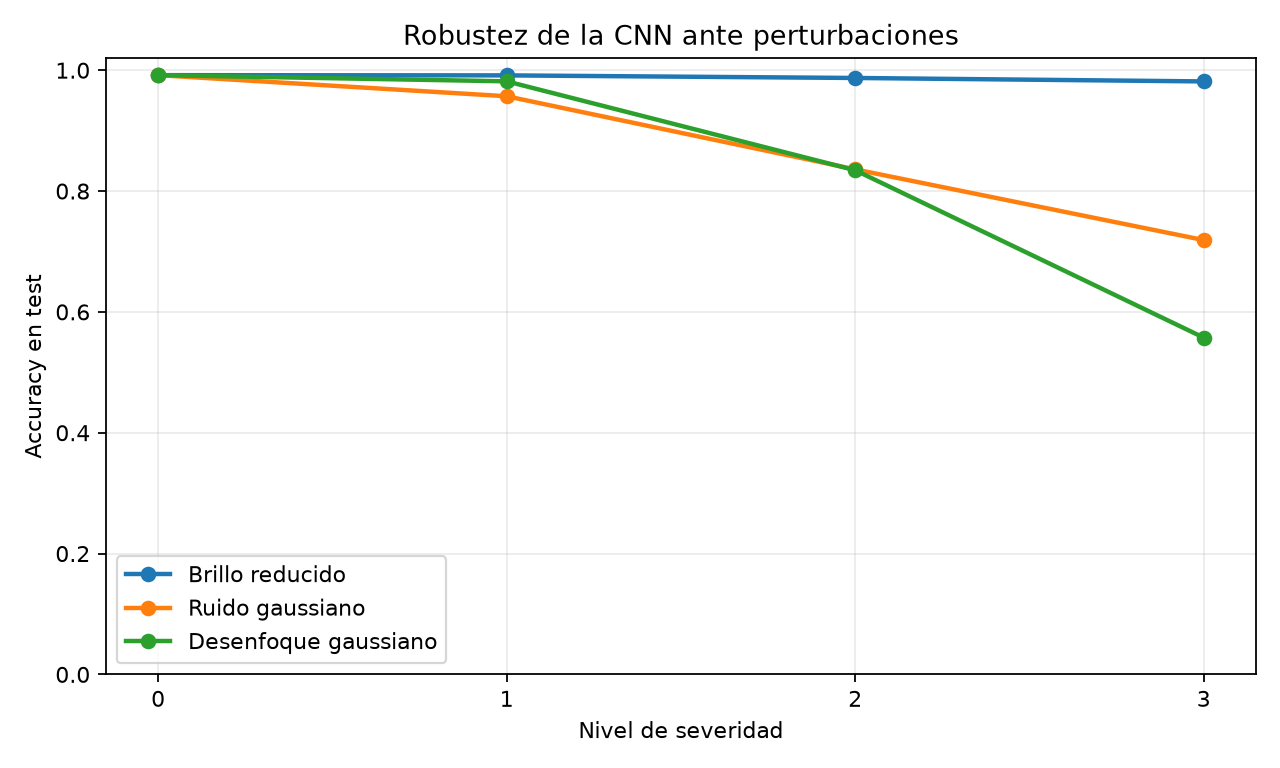

In [3]:
from IPython.display import Image, display
display(Image(filename=ROOT / 'outputs' / 'robustez_curvas.png'))

## Interpretación de resultados

La evaluación de robustez permite cuantificar la resistencia de la CNN ante degradaciones comunes en visión vehicular:

- **Brillo reducido:** Presenta un impacto mínimo. Con la severidad máxima (nivel 3, luminosidad al 34%), el accuracy se mantiene en **0.9815** y el F1 macro en **0.9690**. Las capas convolucionales con Batch Normalization preservan el contraste relativo de los bordes y símbolos incluso bajo condiciones de atardecer o baja iluminación.
- **Ruido gaussiano:** Muestra una degradación moderada y progresiva, descendiendo a **0.8359** en nivel 2 y **0.7188** en nivel 3 (F1 macro de **0.7349**). El ruido granular corrompe los detalles finos de alta frecuencia, dificultando la separación de dígitos en señales con bordes idénticos.
- **Desenfoque gaussiano:** Representa la principal vulnerabilidad del clasificador. El desenfoque severo (radio 2.4 px) reduce el accuracy drásticamente a **0.5574** y el F1 a **0.5945**. Al trabajar con imágenes de 48x48 píxeles, la pérdida de nitidez elimina los trazos y dígitos que diferencian clases con la misma silueta (por ejemplo, límites de velocidad de 30, 50 y 80 km/h).

**Conclusión práctica:** Para un despliegue seguro en asistencia a la conducción (ADAS), el modelo no requiere adaptaciones críticas para variaciones de luz, pero resulta indispensable incorporar desenfoque y ruido sintético durante el aumento de datos para tolerar lluvia, movimiento y lentes desenfocadas.